In [6]:
!pip install --quiet numpy pandas matplotlib pytest hypothesis seaborn

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from decimal import Decimal
from datetime import datetime
import time
import random

from lobx.models import Order, Side, generate_order_id
from lobx.engine import TradingEngine

## Latency

Latency (ms):
  P50: 0.0050
  P95: 0.0187
  P99: 0.0246


Text(0.5, 1.0, 'Latency Distribution')

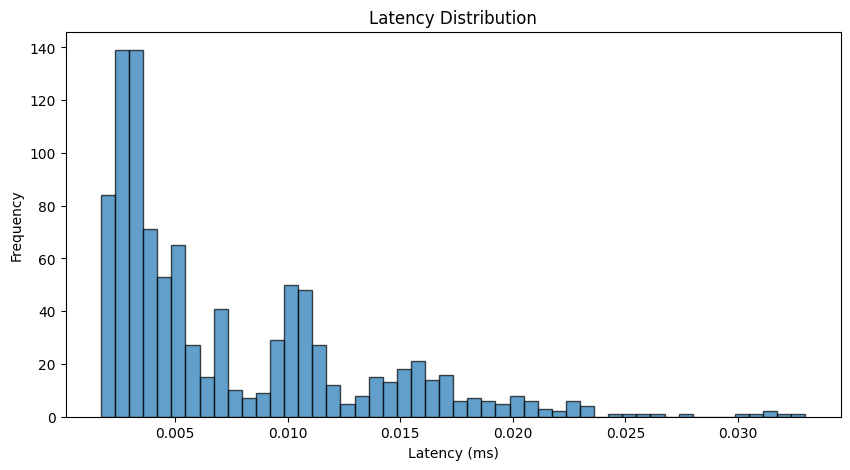

In [8]:
def measure_latency(num_orders=1000):
    random.seed(42)
    engine = TradingEngine(enable_logging=False)
    latencies = []
    
    for i in range(num_orders):
        order = Order(
            order_id=generate_order_id(),
            user_id=f"user{i % 10}",
            symbol="AAPL",
            side=random.choice([Side.BUY, Side.SELL]),
            price=Decimal(str(random.uniform(95.0, 105.0))).quantize(Decimal("0.01")),
            quantity=random.randint(1, 100),
            timestamp=datetime.now()
        )
        
        start = time.perf_counter()
        engine.submit_order(order)
        latencies.append((time.perf_counter() - start) * 1000)
    
    return np.array(latencies)

latencies = measure_latency()

print(f"Latency (ms):")
print(f"  P50: {np.percentile(latencies, 50):.4f}")
print(f"  P95: {np.percentile(latencies, 95):.4f}")
print(f"  P99: {np.percentile(latencies, 99):.4f}")

plt.figure(figsize=(10, 5))
plt.hist(latencies, bins=50, edgecolor='black', alpha=0.7)
plt.xlabel('Latency (ms)')
plt.ylabel('Frequency')
plt.title('Latency Distribution')

# Throughput

Peak throughput: 157406 orders/sec


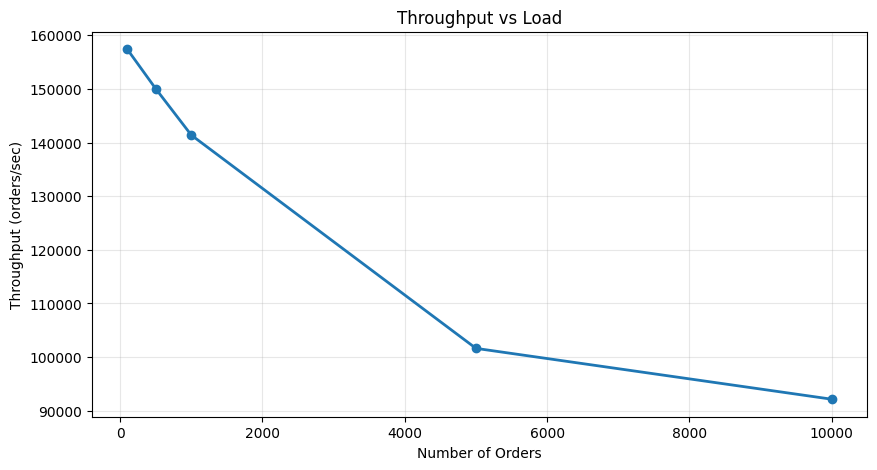

In [ ]:
def measure_throughput(num_orders):
    random.seed(42)
    engine = TradingEngine(enable_logging=False)
    
    orders = [
        Order(
            order_id=generate_order_id(),
            user_id=f"user{i % 10}",
            symbol="AAPL",
            side=random.choice([Side.BUY, Side.SELL]),
            price=Decimal(str(random.uniform(95.0, 105.0))).quantize(Decimal("0.01")),
            quantity=random.randint(1, 100),
            timestamp=datetime.now()
        )
        for i in range(num_orders)
    ]
    
    start = time.perf_counter()
    for order in orders:
        engine.submit_order(order)
    elapsed = time.perf_counter() - start
    
    return num_orders / elapsed if elapsed > 0 else 0

loads = [100, 500, 1000, 5000, 10000]
throughputs = [measure_throughput(load) for load in loads]

print(f"Peak throughput: {max(throughputs):.0f} orders/sec")

plt.figure(figsize=(10, 5))
plt.plot(loads, throughputs, marker='o', linewidth=2)
plt.xlabel('Number of Orders')
plt.ylabel('Throughput (orders/sec)')
plt.title('Throughput vs Load')
plt.grid(True, alpha=0.3)

## FIFO Fairness

In [10]:
engine = TradingEngine(enable_logging=False)

# Submit orders at same price
for i in range(10):
    order = Order(
        order_id=f"BUY{i}",
        user_id=f"user{i}",
        symbol="AAPL",
        side=Side.BUY,
        price=Decimal("100.00"),
        quantity=10,
        timestamp=datetime.now()
    )
    engine.submit_order(order)

# Match with large sell order
sell_order = Order(
    order_id="SELL1",
    user_id="seller",
    symbol="AAPL",
    side=Side.SELL,
    price=Decimal("100.00"),
    quantity=100,
    timestamp=datetime.now()
)
trades = engine.submit_order(sell_order)

# Check FIFO
violations = sum(1 for i, t in enumerate(trades) if t.buy_order_id != f"BUY{i}")
print(f"FIFO compliance: {'PASS' if violations == 0 else 'FAIL'}")
print(f"Trades in correct order: {len(trades) - violations}/{len(trades)}\n")

FIFO compliance: PASS
Trades in correct order: 10/10



## Summary

In [11]:
print(f"Latency P99: {np.percentile(latencies, 99):.4f} ms")
print(f"Peak Throughput: {max(throughputs):.0f} orders/sec")
print(f"FIFO Fairness: {'PASS' if violations == 0 else 'FAIL'}")

Latency P99: 0.0246 ms
Peak Throughput: 157406 orders/sec
FIFO Fairness: PASS
